# Corrected Pythia direction reassessment
Consumes the validated September 12 census/nested-F tables and September 14 Pythia supplement. No historical-target fallback and no OLMo certification. Regenerate tables with `uv run python docs/paper/analyze_corrected_directions.py` and `uv run python -m docs.paper.analyze_pythia_corrections`.

Interpretation: fixed-spectrum replacements identify direction dependence; teacher recovery is stronger than student recovery. Fixed-F and fixed-S ladders test different joint spectrum changes, not independent effects of rank and the other norm. Three injection draws are not three trained populations.

In [1]:
from pathlib import Path
import hashlib, json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
old = root / 'docs/paper/evidence/direction_corrected_20260912'
new = root / 'docs/paper/evidence/pythia_corrected_20260914'
provenance = json.loads((new / 'provenance.json').read_text())
assert provenance['pythia_supplement_complete']
# exact bytes, or a PEFT adapter_config.json differing only in set-valued field order
from subliminal_learning.utils.provenance import verify_evidence_folder
for folder in (old, new):
    print(folder.name + ':', verify_evidence_folder(folder).summary())
census = pd.read_csv(old / 'census_summary.csv')
fro = pd.read_csv(old / 'frobenius_injections.csv')
spec = pd.read_csv(new / 'spectral_observations.csv')
display(census[census.original_failed & census.variant.isin(['rand0', 'top1', 'top4', 'rest4'])])

,arm,original_failed,variant,n,below_cut,median_ce,median_paired_change,mean_trait
9,m410cross,True,rand0,27,22,1.461257,-6.519778,3.911415e-03
12,m410cross,True,rest4,19,9,5.864057,-2.434401,2.845280e-03
13,m410cross,True,top1,24,17,4.158990,-4.492020,1.821765e-03
15,m410cross,True,top4,19,19,1.185215,-6.565724,6.182336e-03
25,m410same,True,rand0,60,41,4.058666,-8.497996,3.518371e-03
28,m410same,True,rest4,39,8,11.187907,-2.003174,1.324756e-02
29,m410same,True,top1,53,16,7.491408,-4.431261,3.186207e-03
31,m410same,True,top4,39,29,3.544664,-8.635722,5.353318e-03
41,samemodel,True,rand0,174,53,8.107367,-6.816644,6.987852e-04
44,samemodel,True,rest4,89,5,14.041480,-1.943789,9.473560e-02


## Opposite endpoint trends under different norm constraints
Left: fixed F/θ = 1, spectral norm decreases with k. Right: fixed S/θ = 0.25, Frobenius norm increases with k. These doses are deliberately labelled, not treated as matched controls. Thin lines are the three paired random frames on the ds1 receiver; the dashed line is the behavioral cutoff. All module frames are nested across k and dose.

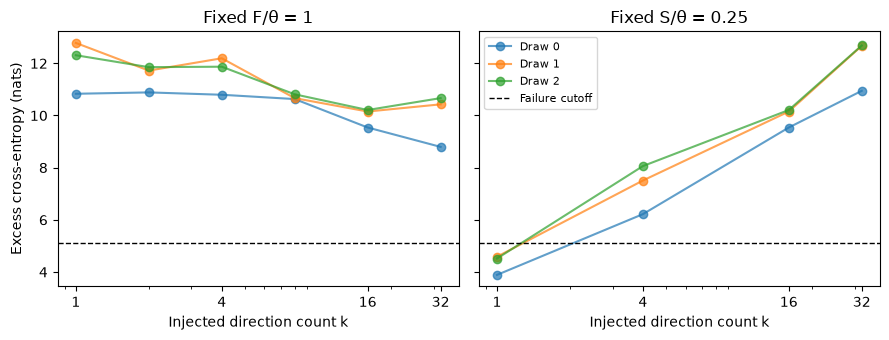

,receiver,seed,E,1,4,16,32,change_32_minus_1
0,EleutherAI/pythia-160m-data-seed1,0,0.25,3.888705,6.217860,9.539476,10.946350,7.057645
1,EleutherAI/pythia-160m-data-seed1,0,0.50,6.978679,10.794631,13.900909,13.957579,6.978901
2,EleutherAI/pythia-160m-data-seed1,0,1.00,10.832928,14.066061,17.121873,15.878954,5.046026
3,EleutherAI/pythia-160m-data-seed1,0,2.00,14.576669,16.398380,17.042917,15.863052,1.286383
4,EleutherAI/pythia-160m-data-seed1,1,0.25,4.585699,7.507009,10.152089,12.671774,8.086076
5,EleutherAI/pythia-160m-data-seed1,1,0.50,8.816988,12.193827,13.850973,15.474226,6.657238
6,EleutherAI/pythia-160m-data-seed1,1,1.00,12.781962,15.805884,14.547910,16.531939,3.749977
7,EleutherAI/pythia-160m-data-seed1,1,2.00,15.309294,17.793599,15.663089,16.761881,1.452587
8,EleutherAI/pythia-160m-data-seed1,2,0.25,4.517120,8.060384,10.210442,12.683960,8.166840
9,EleutherAI/pythia-160m-data-seed1,2,0.50,8.626173,11.870693,13.595588,15.321923,6.695750


In [2]:
ds1 = 'EleutherAI/pythia-160m-data-seed1'
cut = pd.read_csv(old / 'census_observations.csv').query("arm == 'strip'").cut.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
panels = [(fro[(fro.receiver == ds1) & (fro['align'] == 'g') & (fro.E == 1)], 'Fixed F/θ = 1'), (spec[spec.E == .25], 'Fixed S/θ = 0.25')]
for ax, (data, title) in zip(axes, panels):
    for seed, group in data.groupby('seed'):
        group = group.sort_values('k')
        ax.plot(group.k, group.delta_ce, 'o-', alpha=.7, label=f'Draw {seed}')
    ax.axhline(cut, color='black', linestyle='--', linewidth=1, label='Failure cutoff')
    ax.set(xscale='log', xlabel='Injected direction count k', title=title)
    ax.set_xticks([1, 4, 16, 32], ['1', '4', '16', '32'])
axes[0].set_ylabel('Excess cross-entropy (nats)')
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(new / 'pythia_norm_constraints.png', dpi=180)
plt.show()
display(pd.read_csv(new / 'spectral_endpoints.csv'))

## Selected interpolation and threshold-selector evidence
All 12 sampled interpolation curves decrease at every sampled step, but this historical cohort is not a population census. Super/subcritical selectors preserve the final spectrum; they do not match edited component count/energy or directly remove measured intruders. An empty selector is omitted, not a successful intervention.

In [3]:
curves = pd.read_csv(new / 'progression_curves.csv')
assert len(curves) == 12
display(curves.drop(columns='run'))
selectors = pd.read_csv(new / 'selectors_summary.csv')
display(selectors[selectors.original_failed])
pairs = pd.read_csv(new / 'selector_pairs.csv')
display(pairs.groupby('arm').agg(runs=('run', 'size'), empty_super=('n_super', lambda x: (x == 0).sum()), median_super=('n_super', 'median'), median_total=('n_dirs', 'median')))

,orig,rand0,randt0.25,randt0.5,randt0.75,monotone_decreasing,endpoint_change
0,8.668313,2.236308,7.066178,4.027838,2.567005,True,-6.432005
1,1.773791,0.282123,1.351844,0.735162,0.451177,True,-1.491668
2,2.110638,0.429690,1.745462,1.042486,0.623446,True,-1.680947
3,5.712630,1.450715,5.149129,2.542748,1.631619,True,-4.261915
4,6.291909,0.931617,4.969273,2.051653,1.239786,True,-5.360292
5,1.727055,0.460424,1.504358,0.983006,0.699178,True,-1.266632
6,13.885784,1.932830,10.255684,4.182138,2.649873,True,-11.952954
7,3.944252,1.542455,3.223433,2.055747,1.862035,True,-2.401798
8,8.856191,1.051709,6.384806,2.377997,1.435581,True,-7.804482
9,2.633777,0.489574,2.195430,1.208545,0.734775,True,-2.144203


,arm,original_failed,variant,n,below_cut,median_ce,median_paired_change,mean_trait
4,m410cross,True,orig,22,0,8.876869,0.000000,5.107558e-04
5,m410cross,True,rand0,22,22,0.948267,-6.990241,4.766725e-03
6,m410cross,True,sub,22,20,1.413981,-6.001981,4.046963e-03
7,m410cross,True,super,21,9,5.811287,-3.645597,1.139107e-03
12,m410same,True,orig,39,0,11.638005,0.000000,2.019832e-03
13,m410same,True,rand0,39,37,2.481383,-8.730091,5.341947e-03
14,m410same,True,sub,39,24,3.769861,-6.485069,1.302703e-02
15,m410same,True,super,39,13,7.580494,-3.959283,4.237500e-03
20,samemodel,True,orig,53,0,11.857960,0.000000,2.092071e-01
21,samemodel,True,rand0,53,51,2.867113,-9.021819,2.152583e-03


,runs,empty_super,median_super,median_total
arm,,,,
m410cross,47,3,65.0,1536.0
m410same,67,2,95.0,1536.0
samemodel,83,7,33.0,384.0
strip,141,10,38.0,768.0
teachers,147,145,0.0,768.0
traitfree,61,1,65.0,384.0
